In [ ]:

#UNRST_file(root).as_Xfiles(log=print, stop=10)

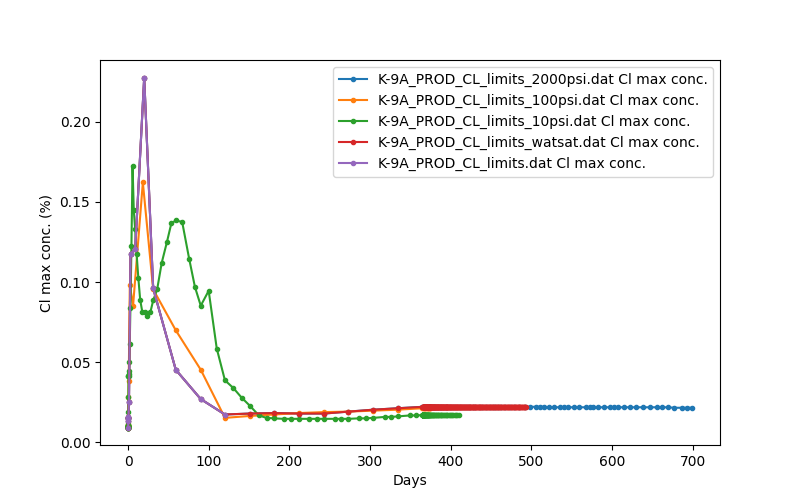

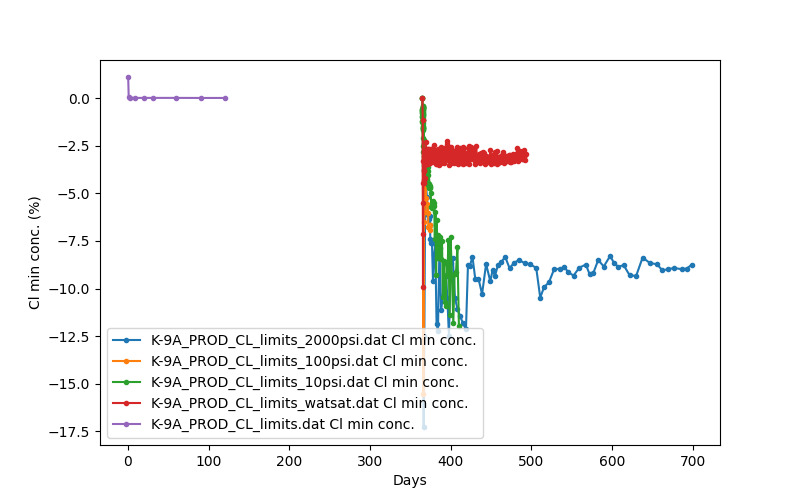

In [1]:
from pathlib import Path
import matplotlib.pyplot as pl
import numpy as np

cop = Path('/home/shared/owner/CoP_files')
root = cop/'input/K-9A_PROD/K-9A_PROD'

%matplotlib widget

def plot_cl_limits(*dat_files):
    size = (8, 5)
    pl.figure(figsize=size)
    for dat_file in dat_files:
        cl_limits = np.genfromtxt(dat_file)
        days = cl_limits[::2, 0]
        pl.plot(days, 100 * ((cl_limits[::2, 2] / cl_limits[::2, 1]) - 1), '-o', ms=3, label=f'{dat_file.name} Cl max conc.')
        #pl.plot(days, cl_limits[::2, 4], label=f'{dat_file.name} >0.1')
    pl.legend()
    pl.xlabel('Days')
    #pl.ylabel('Cells above 0.1% of max limit')
    pl.ylabel('Cl max conc. (%)')
    
    pl.figure(figsize=size)
    for dat_file in dat_files:
        cl_limits = np.genfromtxt(dat_file)
        a = next((1+2*i for i, day in enumerate(cl_limits[1::2, 0]) if day > 360), 11)
        b = next((1+2*i for i, day in enumerate(cl_limits[1::2, 0]) if day > 1000), len(cl_limits))
        days = cl_limits[a:b:2, 0]
        pl.plot(days, 100 * ((cl_limits[a:b:2, 2] / cl_limits[a:b:2, 1]) - 1), '-o', ms=3, label=f'{dat_file.name} Cl min conc.')
        #pl.plot(days, cl_limits[a::2, 4], label=f'{dat_file.name} >0.1')
    pl.xlabel('Days')
    #pl.ylabel('Cells above 0.1% of max limit')  
    pl.ylabel('Cl min conc. (%)')
    pl.legend()

files = ('K-9A_PROD_CL_limits_2000psi.dat', 
         'K-9A_PROD_CL_limits_100psi.dat', 
         'K-9A_PROD_CL_limits_10psi.dat', 
         'K-9A_PROD_CL_limits_watsat.dat',
         'K-9A_PROD_CL_limits.dat')

plot_cl_limits(*(root.parent / file for file in files))
    


In [3]:
from pathlib import Path
import matplotlib.pyplot as pl
import numpy as np

from IORlib.ECL import UNRST_file

cop = Path('/home/shared/owner/CoP_files')
root = cop/'input/K-9A_PROD/K-9A_PROD'

%matplotlib widget

unrst = UNRST_file(root)
list(unrst.steps())

[11, 12, 13, 14]

In [ ]:
from IORlib.utils import molL2ppm, ppm2molL
from molmass import Formula

lsw_mol = {'Na+':0.013, 'Ca+2':0.003, 'Cl-': 0.013, 'SO4-2':0.001}

lsw_ppm = {ion:molL2ppm(ion)*conc for ion,conc in lsw_mol.items()}
lsw_chrg = {ion:Formula(ion).charge*conc for ion,conc in lsw_mol.items()}
print(lsw_ppm)
print(sum(lsw_ppm.values()))
print(lsw_chrg)
print(sum(lsw_chrg.values()))



In [ ]:
lsw2_ppm = {'Na+':306, 'K+':8, 'Ca+2':24, 'Mg+2':10, 'Cl-':651, 'SO4-2':1}
lsw2_mol = {ion:ppm2molL(ion)*conc for ion,conc in lsw2_ppm.items()}
print(lsw2_mol)
